# Renta del 50 % de la población con menos renta

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"               # carpeta en research/temas/
GRAFICA_ID = "renta-50-inferior"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Renta del 50 % de la población con menos renta"  # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Estándares de poder adquisitivo (PPS) por persona y año, a precios de 2015"
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 0               # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La **renta disponible media de la mitad de la población con menos renta**: se ordena a toda la población por su renta disponible equivalente (la del hogar, después de impuestos directos y prestaciones, ajustada por el tamaño del hogar) y se calcula la media del 50 % de abajo. Se expresa en **estándares de poder adquisitivo (PPS)**, la moneda de Eurostat con la misma capacidad de compra en todos los países de la UE, descontada la inflación.

**Para qué sirve.** El PIB por habitante y la renta media pueden crecer aunque esa mejora no llegue a la mitad con menos renta. Esta serie muestra cuánto ha mejorado (o empeorado) la renta de esa mitad, en España y en la UE-27, en términos que se pueden comparar entre países y entre años. Las notas dan qué parte de la renta total recibe ese 50 % y el 10 % con más renta.

**Cálculo propio.** Eurostat no publica la media de la mitad inferior: publica la parte de la renta total que recibe cada decil y la renta media. La media del 50 % inferior es la parte de los cinco primeros deciles por la renta media y por dos (METODOLOGIA §2.3, pendiente de aprobación). El dos sale de que esa mitad es la mitad de la población: si la renta media de toda la población es la renta total entre `N` personas, los cinco primeros deciles reciben `parte × renta media × N` entre `N / 2` personas, es decir, `parte × renta media × 2` por persona.

**Limitaciones.**
- Mide la renta monetaria; no incluye el valor de los servicios públicos ni la riqueza.
- Las encuestas recogen mal las rentas más altas: la parte del 10 % superior está infraestimada.
- Solo España y la UE-27: la OCDE no publica la renta por deciles para EE. UU. y Canadá.

## 2. Descarga

- **Eurostat, encuesta de condiciones de vida** (`ilc_di01`): parte de la renta disponible equivalente total que recibe cada decil (`statinfo=SHARE`, deciles `D1` a `D10`).
- **Eurostat** (`ilc_di03`): renta disponible equivalente media (`MEAN_EI`), población total, en PPS.
- **Eurostat, índice de precios de consumo armonizado** (`prc_hicp_aind`): índice general (`CP00`) de la UE-27, media anual, 2015 = 100, para descontar la inflación de los PPS (que se miden a precios de cada año).

Para España y la UE-27 (`EU27_2020`), desde la encuesta de 2004 (la de 1995 a 2001 era otra encuesta, el Panel de Hogares de la UE, y no se usa).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

from datetime import date

import pandas as pd

from lib import estilos, eurostat
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

HOY = date.today().isoformat()
GEOS = {"ES": "espana", "EU27_2020": "ue27"}
DESDE_SILC = 2004  # primera encuesta de condiciones de vida (EU-SILC) de España
DECILES = [f"D{i}" for i in range(1, 11)]

partes = []
for d in DECILES:
    s, _ = eurostat.get("ilc_di01", {"freq": "A", "quant_inc": d, "statinfo": "SHARE", "unit": "PPS"}, geos=GEOS, desde=DESDE_SILC)
    partes.append(s.assign(decil=d))
cuotas = pd.concat(partes, ignore_index=True)
media, _ = eurostat.get("ilc_di03", {"freq": "A", "age": "TOTAL", "sex": "T", "statinfo": "MEAN_EI", "unit": "PPS"},
                        geos=GEOS, desde=DESDE_SILC)
estados, etiquetas = eurostat.get_estados("ilc_di03", {"freq": "A", "age": "TOTAL", "sex": "T", "statinfo": "MEAN_EI", "unit": "PPS"},
                                          geos=GEOS, desde=DESDE_SILC)
ipca, _ = eurostat.get("prc_hicp_aind", {"freq": "A", "coicop": "CP00", "unit": "INX_A_AVG"}, geos={"EU27_2020": "ipca"}, desde=DESDE_SILC - 1)
print(media.groupby("serie")["periodo"].agg(["min", "max", "count"]))
print("Marcas de la renta media:", estados[estados["estado"].str.contains("b")].to_string(index=False), etiquetas)

         min   max  count
serie                    
espana  2004  2025     22
ue27    2011  2025     15
Marcas de la renta media:  serie  periodo estado
espana     2004      b
espana     2008      b {'b': 'break in time series', 'e': 'estimated'}


## 3. Transformación

1. **Parte del 50 % inferior** = suma de las partes de los deciles 1 a 5 (en % de la renta total). Se comprueba que los diez deciles suman 100.
2. **Renta media del 50 % inferior** (PPS de cada año) = parte del 50 % inferior / 100 × renta media × 2. Se multiplica por dos porque esa parte de la renta total (renta media × `N` personas) se reparte entre la mitad de la población (`N / 2`), no entre toda: la renta media de la mitad inferior es `parte × renta media × N / (N / 2)`. Ejemplo: si recibiera exactamente el 50 % de la renta total, su media sería igual a la de toda la población (50 % × 2 = 1).
3. **Año de la renta.** La encuesta de cada año recoge la renta del año anterior: cada dato se fecha con el año de la renta (encuesta − 1), como en `gini-renta-disponible`.
4. **Precios constantes.** Los PPS de Eurostat están a precios de cada año: se dividen por el índice de precios de consumo armonizado de la UE-27 del año de la renta (2015 = 100) y se multiplican por 100.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


ancho = cuotas.pivot_table(index=["serie", "periodo"], columns="decil", values="valor")
ancho = ancho.dropna(subset=DECILES)
suma = ancho[DECILES].sum(axis=1)
assert suma.between(99, 101).all(), f"Los deciles no suman 100: {suma[~suma.between(99, 101)]}"
cuota_50 = ancho[[f"D{i}" for i in range(1, 6)]].sum(axis=1)
cuota_10 = ancho["D10"]
m = media.set_index(["serie", "periodo"])["valor"]
nominal = (cuota_50 / 100 * m.reindex(cuota_50.index) * 2).dropna()
renta = nominal.reset_index(name="valor")
renta["periodo"] = renta["periodo"] - 1  # año de la encuesta -> año de la renta
indice = ipca.set_index("periodo")["valor"]
renta["valor"] = renta["valor"] / renta["periodo"].map(indice) * 100
renta = renta.dropna(subset=["valor"])

vacias = pd.DataFrame({"serie": ["ocde", "eeuu", "canada"], "periodo": [DESDE] * 3, "valor": [float("nan")] * 3})
df = pd.concat([renta[["serie", "periodo", "valor"]], vacias], ignore_index=True)

fuente = "ilc_di01 (SHARE, D1-D5), ilc_di03 (MEAN_EI, PPS) y prc_hicp_aind (CP00, INX_A_AVG, EU27_2020): cálculo propio"
fuentes = [
    *[FuenteMeta(s, eurostat.ORGANISMO, fuente, eurostat.URL_DATABROWSER.format(dataset="ilc_di01"), HOY) for s in ("espana", "ue27")],
    *[FuenteMeta(s, eurostat.ORGANISMO, "sin dato: la OCDE no publica la renta por deciles y Eurostat solo cubre Europa",
                 eurostat.URL_DATABROWSER.format(dataset="ilc_di01"), HOY) for s in ("ocde", "eeuu", "canada")],
]

# Parte de la renta del 50 % inferior y del 10 % superior en España: primera y última encuesta
c50, c10 = cuota_50.xs("espana"), cuota_10.xs("espana")
a0, a1 = int(c50.index.min()), int(c50.index.max())
rupturas = sorted(estados.loc[(estados["serie"] == "espana") & estados["estado"].str.contains("b"), "periodo"].astype(int))
rupturas = [r for r in rupturas if r > DESDE_SILC]  # la marca del primer año solo indica el inicio de la encuesta
NOTAS = [
    "Cálculo propio (METODOLOGIA §2.3, pendiente de aprobación en la revisión humana) con la encuesta de condiciones de "
    "vida de Eurostat (EU-SILC): renta media del 50 % de la población con menos renta disponible equivalente = parte de "
    "la renta total de los deciles 1 a 5 (ilc_di01) × renta disponible equivalente media en PPS (ilc_di03) × 2 (la parte se reparte entre la mitad de la población, no entre toda).",
    "Año de la renta: cada encuesta recoge la renta del año anterior y aquí se fecha con el año de la renta. Precios "
    "constantes: los PPS de cada año se dividen por el índice de precios de consumo armonizado de la UE-27 "
    "(prc_hicp_aind, 2015 = 100).",
    f"Parte de la renta total que recibe en España el 50 % con menos renta: {es(c50[a0])} % en la encuesta de {a0} y "
    f"{es(c50[a1])} % en la de {a1}; el 10 % con más renta, {es(c10[a0])} % y {es(c10[a1])} %.",
    "Desde la encuesta de 2004 (la primera EU-SILC de España); la UE-27 desde la primera encuesta con el agregado de la "
    "composición actual.",
    "OCDE, Estados Unidos y Canadá: sin dato; la Income Distribution Database de la OCDE no publica la renta por deciles.",
    "Las encuestas recogen mal las rentas más altas, y no incluyen el valor de los servicios públicos ni la riqueza.",
]
if rupturas:
    NOTAS.append(
        "Eurostat marca ruptura de serie en la renta media de España en la encuesta de "
        + ", ".join(map(str, rupturas))
        + ": los años anteriores no son del todo comparables con los siguientes."
    )

## 4. Visualización

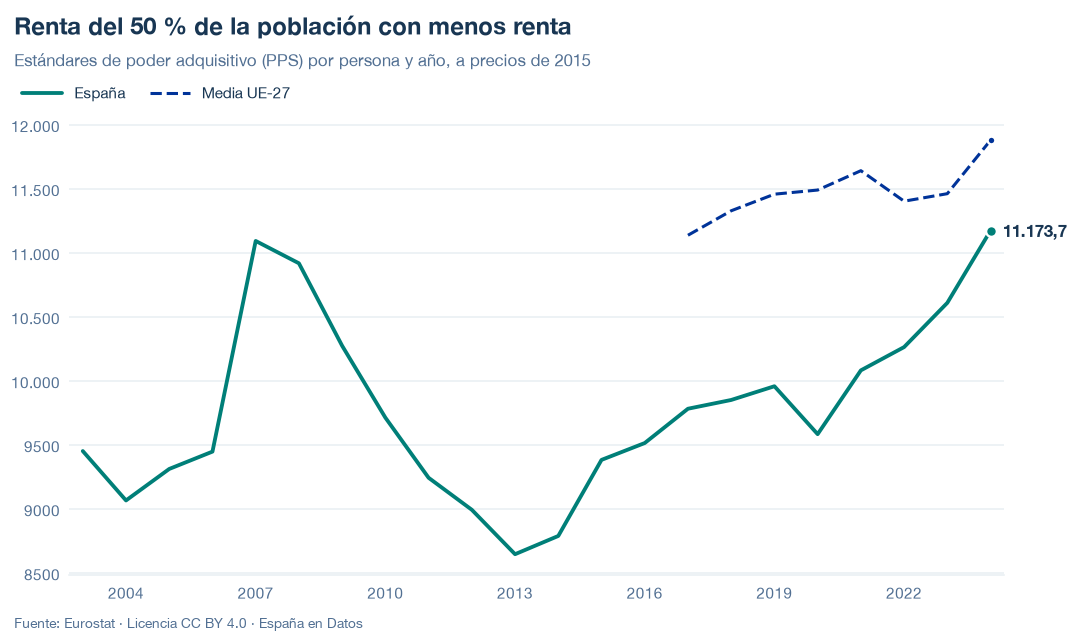

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/renta-50-inferior.json y data/renta-50-inferior.csv


## 6. Fuentes, notas y licencia

- Eurostat, encuesta de condiciones de vida: `ilc_di01` (`SHARE`, `D1` a `D10`) e `ilc_di03` (`MEAN_EI`, `PPS`, `TOTAL`, `T`).
- Eurostat, `prc_hicp_aind` (`CP00`, `INX_A_AVG`, `EU27_2020`).

La fecha de consulta de cada serie está en `fuentes` del JSON; `writer.py` añade a las notas el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.